# Generalized Evolution Strategies for Mixed-Variable Optimization

## Experiment 1: Equal-Budget Benchmark Comparison

> Prototype 1 vs Baseline Optimizers (Isotropic ES and CMA-ES)

> This notebook compares Prototype 1 (our custom heterogeneous ES model) against the following baseline implementations:
1. **Isotropic ES (Simple Self-Adaptive)**: Uses a single global $\sigma$ ($n_\sigma = 1$, $n_\alpha = 0$).
2. **sep-CMA-ES (Separable CMA-ES)**: Diagonal CMA-ES from the `pycma` library (`CMA_diagonal=True`).
3. **Standard CMA-ES (Upper Bound)**: Full-covariance CMA-ES used strictly as a performance ceiling.

All comparisons use the **real-valued block only** for fairness, evaluated on
standard benchmark functions with equal evaluation budgets and 10 seeds.

In [29]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import cma

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = None
for parent in [cwd] + list(cwd.parents):
    if (parent / "src").is_dir():
        project_root = parent
        break
if project_root is None:
    project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.es_model.config import ESConfig
from src.es_model import kernels
from src.es_model.engine import Individual, HeterogeneousES, create_random_individual, clone_individual, mutate_individual, select_survivors
from src.benchmarks.functions import BENCHMARKS
from src.runners import custom_es, isotropic_es, sep_cma_es, standard_cma_es

## 2. Benchmark Functions

Each function accepts a 1-D numpy array of shape `(n,)` and returns a scalar.
Global minimum is 0.0 at the origin (or known point) for all functions.

In [30]:
# BENCHMARKS is imported from src.benchmarks.functions
print(f"Loaded {len(BENCHMARKS)} benchmark definitions from src.benchmarks")

Loaded 4 benchmark definitions from src.benchmarks


In [31]:
# --- Verify global minima ---
DIM = 2
for name, info in BENCHMARKS.items():
    x_opt = info['optimum'](DIM)
    val = info['fn'](x_opt)
    assert abs(val) < 1e-10, f"{name} failed: f(optimum) = {val}"
    print(f"  {name:12s} f(optimum) = {val:.2e} ✓")
print("\nAll benchmark functions verified.")

  Sphere       f(optimum) = 0.00e+00 ✓
  Rastrigin    f(optimum) = 0.00e+00 ✓
  Rosenbrock   f(optimum) = 0.00e+00 ✓
  Ackley       f(optimum) = 4.44e-16 ✓

All benchmark functions verified.


## 3. Runner Wrappers & Experiment Execution

Each runner is imported from `src.runners` and implements the standard interface:
`run(fn, dim, bounds, seed, max_evals, **kwargs) -> np.ndarray`
returning a 1-D array of best-fitness values indexed by evaluation count.

We configure and run all baseline optimizers and Prototype 1 across all benchmark functions.

In [32]:
# Experiment parameters
# Set SMOKE_RUN = True for quick validation (Phase 1), False for production results (Phase 2)
SMOKE_RUN = False

DIM = 10
if SMOKE_RUN:
    MAX_EVALS = 1_000
    N_SEEDS = 2
    print(">>> PHASE 1: Smoke Validation Mode (1,000 evaluations, 2 seeds)")
else:
    MAX_EVALS = 10_000
    N_SEEDS = 10
    print(">>> PHASE 2: Production Run Mode (10,000 evaluations, 10 seeds)")

SEEDS = list(range(1, N_SEEDS + 1))


# --- All runners registry ---
RUNNERS = {
    'Prototype 1':                          custom_es.run,
    'Isotropic ES (Simple Self-Adaptive)':  isotropic_es.run,
    'sep-CMA-ES (Separable CMA-ES)':        sep_cma_es.run,
    'Standard CMA-ES (Upper Bound)':        standard_cma_es.run,
}

>>> PHASE 2: Production Run Mode (10,000 evaluations, 10 seeds)


In [33]:
def run_all_experiments(benchmarks, runners, dim, max_evals, seeds):
    results = {}
    for bname, binfo in benchmarks.items():
        results[bname] = {}
        b_dim = binfo.get("dim", dim)
        for rname, runner in runners.items():
            traces = []
            for seed in seeds:
                if rname == "Prototype 1":
                    proto_config = ESConfig(
                        n_real=b_dim,
                        n_count=0,
                        n_binary=0,
                        n_categorical=0,
                        n_fuzzy=0,
                        lower_bound_real=float(binfo["bounds"][0]),
                        upper_bound_real=float(binfo["bounds"][1]),
                        seed=seed,
                    )
                    trace = runner(binfo["fn"], b_dim, binfo["bounds"], seed, max_evals, config=proto_config)
                else:
                    trace = runner(binfo["fn"], b_dim, binfo["bounds"], seed, max_evals)
                traces.append(trace)
            results[bname][rname] = np.array(traces)
            median_final = np.median(results[bname][rname][:, -1])
            print(f"  {bname:12s} | {rname:36s} | median final: {median_final:.4e}")
    return results

print("Running experiments...\n")
results = run_all_experiments(BENCHMARKS, RUNNERS, DIM, MAX_EVALS, SEEDS)
print("\nAll experiments complete.")

# --- Save Experiment 1 results to experiments/data/experiment_1/ ---
if "project_root" not in globals() or project_root is None:
    from pathlib import Path
    cwd = Path.cwd().resolve()
    for parent in [cwd] + list(cwd.parents):
        if (parent / "src").is_dir():
            project_root = parent
            break
    if project_root is None:
        project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd

data_dir = os.path.join(str(project_root), "experiments", "data", "experiment_1")
os.makedirs(data_dir, exist_ok=True)

save_dict = {"seeds": np.array(SEEDS, dtype=np.int64)}
for bname, r_dict in results.items():
    for rname, arr in r_dict.items():
        clean_rname = (
            rname.replace(" ", "_")
            .replace("-", "_")
            .replace("(", "")
            .replace(")", "")
        )
        save_dict[f"{bname}__{clean_rname}"] = arr

output_file = os.path.join(data_dir, "exp1_traces.npz")
np.savez_compressed(output_file, **save_dict)
print(f"Results successfully saved to: {output_file}")


Running experiments...

  Sphere       | Prototype 1                          | median final: 3.0601e-11
  Sphere       | Isotropic ES (Simple Self-Adaptive)  | median final: 2.5641e-10
  Sphere       | sep-CMA-ES (Separable CMA-ES)        | median final: 7.5449e-15
  Sphere       | Standard CMA-ES (Upper Bound)        | median final: 1.6433e-14
  Rastrigin    | Prototype 1                          | median final: 2.4874e+00
  Rastrigin    | Isotropic ES (Simple Self-Adaptive)  | median final: 4.3281e+01
  Rastrigin    | sep-CMA-ES (Separable CMA-ES)        | median final: 1.3432e+01
  Rastrigin    | Standard CMA-ES (Upper Bound)        | median final: 1.4924e+01
  Rosenbrock   | Prototype 1                          | median final: 6.5837e+00
  Rosenbrock   | Isotropic ES (Simple Self-Adaptive)  | median final: 7.1741e+00
  Rosenbrock   | sep-CMA-ES (Separable CMA-ES)        | median final: 1.0475e+00
  Rosenbrock   | Standard CMA-ES (Upper Bound)        | median final: 2.9543e-14
  Ac

## 4. Visualization

For each benchmark function, we plot:
1. **2D Function Landscape (Surface Contour Plot)**: Compact contour map of $f(x_1, x_2)$ showing topologic features (multimodality, steepness, valleys) and the global optimum ($\star$).
2. **Convergence Trajectory**: Median best-so-far fitness over evaluations with IQR (25th–75th percentile) envelope across 10 random seeds in $D=10$.

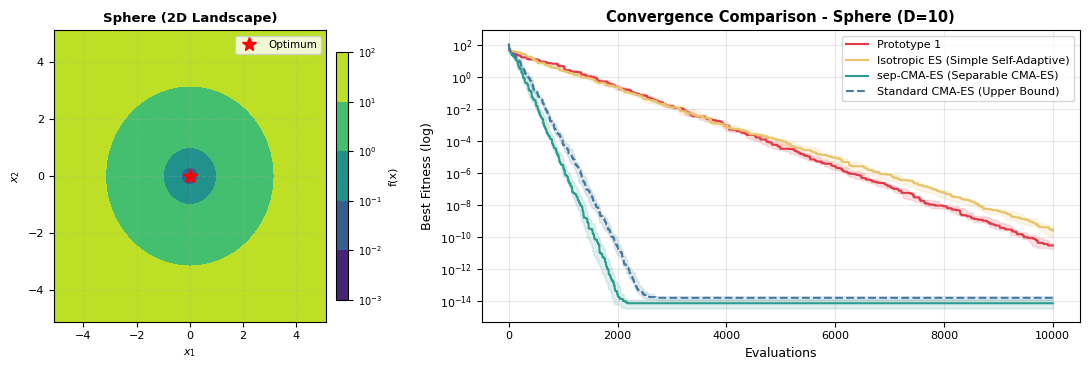

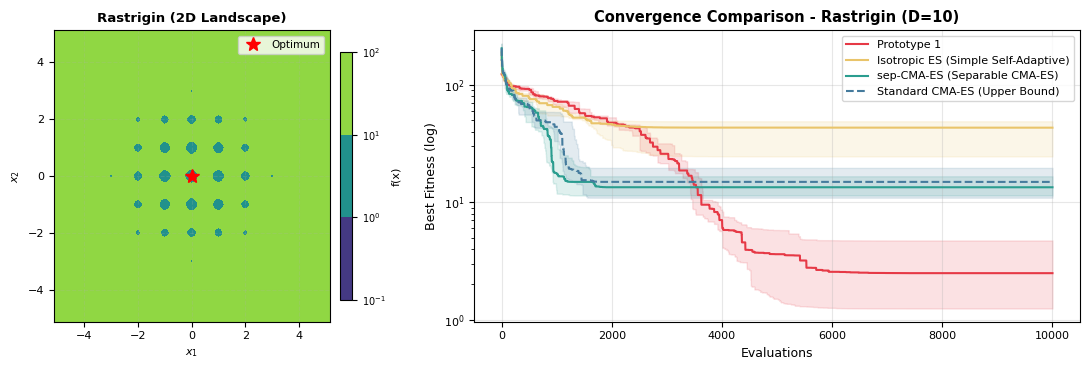

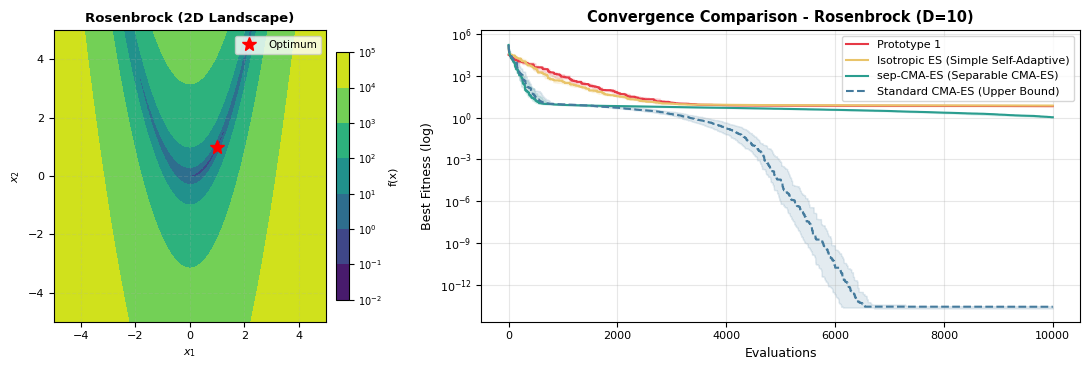

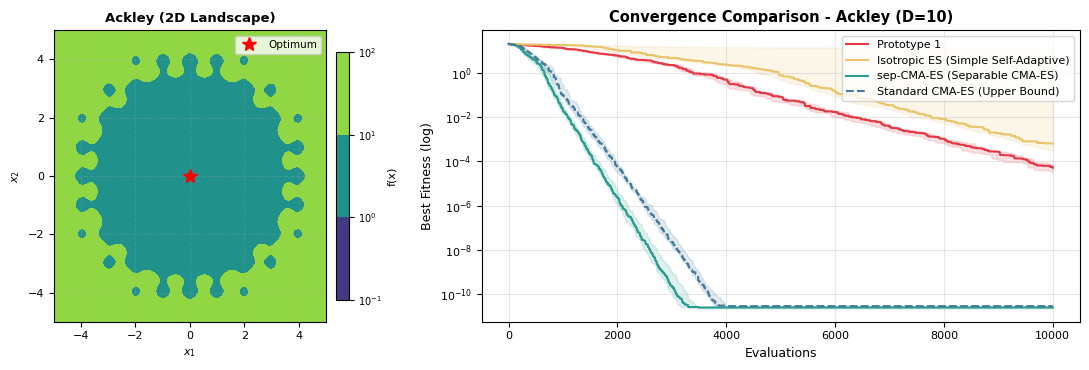

In [34]:
from matplotlib.colors import LogNorm

COLORS = {
    'Prototype 1':                          '#E63946',
    'Isotropic ES (Simple Self-Adaptive)':  '#E9C46A',
    'sep-CMA-ES (Separable CMA-ES)':        '#2A9D8F',
    'Standard CMA-ES (Upper Bound)':        '#457B9D',
}

# Fallback: if results is not in memory, load from saved npz if available
if "results" not in globals():
    if "project_root" not in globals() or project_root is None:
        from pathlib import Path
        cwd = Path.cwd().resolve()
        for parent in [cwd] + list(cwd.parents):
            if (parent / "src").is_dir():
                project_root = parent
                break
        if project_root is None:
            project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd
    data_dir = os.path.join(str(project_root), "experiments", "data", "experiment_1")
    traces_file = os.path.join(data_dir, "exp1_traces.npz")
    if os.path.exists(traces_file):
        loaded = np.load(traces_file)
        results = {}
        for bname in BENCHMARKS.keys():
            results[bname] = {}
            for rname in RUNNERS.keys():
                clean_rname = (
                    rname.replace(" ", "_")
                    .replace("-", "_")
                    .replace("(", "")
                    .replace(")", "")
                )
                key = f"{bname}__{clean_rname}"
                if key in loaded:
                    results[bname][rname] = loaded[key]
        print(f"Loaded existing results from: {traces_file}")


def plot_benchmark_summary(bname: str, binfo: dict, data: dict, max_evals: int) -> None:
    """
    Plot side-by-side with asymmetric width ratios:
      Left:  Compact 2D Function Landscape (Contour Plot).
      Right: Main Convergence Trajectories curve.
    """
    fig, (ax_surf, ax_conv) = plt.subplots(
        1, 2, 
        figsize=(11, 3.8), 
        gridspec_kw={'width_ratios': [1, 1.8]}
    )
    
    # -------------------------------------------------------------
    # 1. Left Panel: Compact 2D Contour Plot of Benchmark Function
    # -------------------------------------------------------------
    bounds = binfo['bounds']
    if bname == "Ackley": # @TODO Temporal fix to view better the plot
        x = np.linspace(-5, 5, 150)
        y = np.linspace(-5, 5, 150)
    else:
        x = np.linspace(bounds[0], bounds[1], 150)
        y = np.linspace(bounds[0], bounds[1], 150)
    X, Y = np.meshgrid(x, y)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = binfo['fn'](np.array([X[i, j], Y[i, j]]))
            
    Z_min = Z.min()
    Z_shift = Z - Z_min + 1e-6 if Z_min <= 0 else Z
    
    cs = ax_surf.contourf(X, Y, Z_shift, levels=25, cmap='viridis', norm=LogNorm())
    cbar = fig.colorbar(cs, ax=ax_surf, pad=0.03, shrink=0.85)
    cbar.set_label('f(x)', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    opt = binfo['optimum'](2)
    ax_surf.plot(opt[0], opt[1], 'r*', markersize=10, label='Optimum', zorder=5)
    ax_surf.set_title(f'{bname} (2D Landscape)', fontsize=9.5, fontweight='bold')
    ax_surf.set_xlabel('$x_1$', fontsize=8)
    ax_surf.set_ylabel('$x_2$', fontsize=8)
    ax_surf.tick_params(labelsize=8)
    ax_surf.grid(True, alpha=0.2, linestyle='--')
    ax_surf.legend(loc='upper right', fontsize=7.5)
    
    # -------------------------------------------------------------
    # 2. Right Panel: Convergence Trajectories
    # -------------------------------------------------------------
    evals = np.arange(1, max_evals + 1)

    for rname, traces in data.items():
        median = np.median(traces, axis=0)
        q25 = np.percentile(traces, 25, axis=0)
        q75 = np.percentile(traces, 75, axis=0)

        color = COLORS.get(rname, '#888888')
        ls = '--' if 'Upper Bound' in rname else '-'
        ax_conv.plot(evals, median, label=rname, color=color, linewidth=1.5, linestyle=ls)
        ax_conv.fill_between(evals, q25, q75, alpha=0.15, color=color)

    ax_conv.set_yscale('log')
    ax_conv.set_xlabel('Evaluations', fontsize=9)
    ax_conv.set_ylabel('Best Fitness (log)', fontsize=9)
    ax_conv.set_title(f'Convergence Comparison - {bname} (D=10)', fontsize=10.5, fontweight='bold')
    ax_conv.legend(loc='upper right', fontsize=8)
    ax_conv.grid(True, alpha=0.3)
    ax_conv.tick_params(labelsize=8)
    
    plt.tight_layout()
    plt.show()


# --- Generate summary plots for all benchmark functions ---
if "results" in globals() and results:
    for bname, binfo in BENCHMARKS.items():
        if bname in results:
            plot_benchmark_summary(bname, binfo, results[bname], MAX_EVALS)
else:
    print("No results available to plot. Run preceding cells or ensure exp1_traces.npz exists.")


## 5. Statistical Results Summary Table


In [35]:
print("=" * 105)
print(f" EXPERIMENT 1 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations | D={DIM})")
print("=" * 105)
print(f"{'Benchmark Function':<22} | {'Runner / Optimizer':<38} | {'Median Best':<18} | {'Min (Best Run)':<18}")
print("-" * 105)

if "results" in globals() and results:
    for bname, r_dict in results.items():
        for rname, arr in r_dict.items():
            med_val = np.median(arr[:, -1])
            min_val = np.min(arr[:, -1])
            print(f"{bname:<22} | {rname:<38} | {med_val:<18.4e} | {min_val:<18.4e}")
        print("-" * 105)
print("=" * 105)


 EXPERIMENT 1 RESULTS SUMMARY (10 Seeds | 10000 Max Evaluations | D=10)
Benchmark Function     | Runner / Optimizer                     | Median Best        | Min (Best Run)    
---------------------------------------------------------------------------------------------------------
Sphere                 | Prototype 1                            | 3.0601e-11         | 1.4394e-11        
Sphere                 | Isotropic ES (Simple Self-Adaptive)    | 2.5641e-10         | 6.4907e-11        
Sphere                 | sep-CMA-ES (Separable CMA-ES)          | 7.5449e-15         | 1.3641e-15        
Sphere                 | Standard CMA-ES (Upper Bound)          | 1.6433e-14         | 7.4788e-15        
---------------------------------------------------------------------------------------------------------
Rastrigin              | Prototype 1                            | 2.4874e+00         | 9.9496e-01        
Rastrigin              | Isotropic ES (Simple Self-Adaptive)    | 4.3281e+01    